# 5 · Cross-cutting: latency, the free-text metric, difficulty, and statistics

*Part 5 of the story. Previously: `04_relations.ipynb`.*

**What this notebook answers.** The secondary measurements behind the pilot:
how fast were the variants, how fair is the free-text metric for variant A,
where in the candidate list does difficulty live, and how much can we trust
the C-vs-D difference statistically?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 220)


FULL = al.find_run("skeleton")
CAP1 = al.find_run("cap1")
CAP3 = al.find_run("cap3")
full = al.load_answers(FULL)
cap1 = al.load_answers(CAP1)
cap3 = al.load_answers(CAP3)
senses = al.load_senses_table().set_index("sense_id")
questions = al.load_questions_table().set_index("question_id")
run_of = {1: CAP1, 2: al.find_run("cap2"), 3: CAP3, 12: FULL}

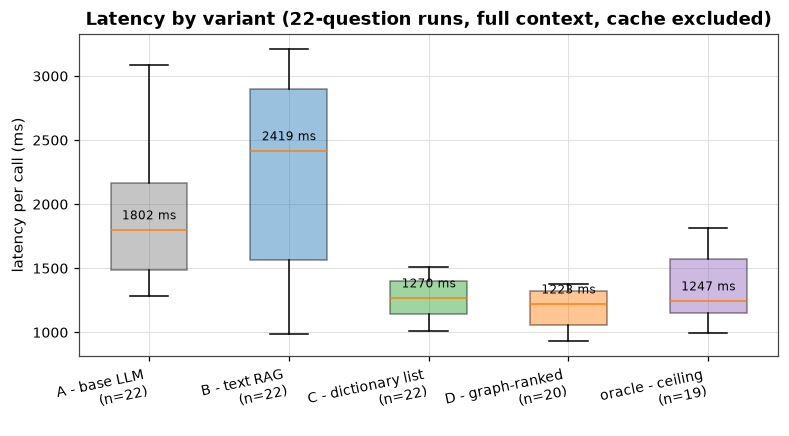

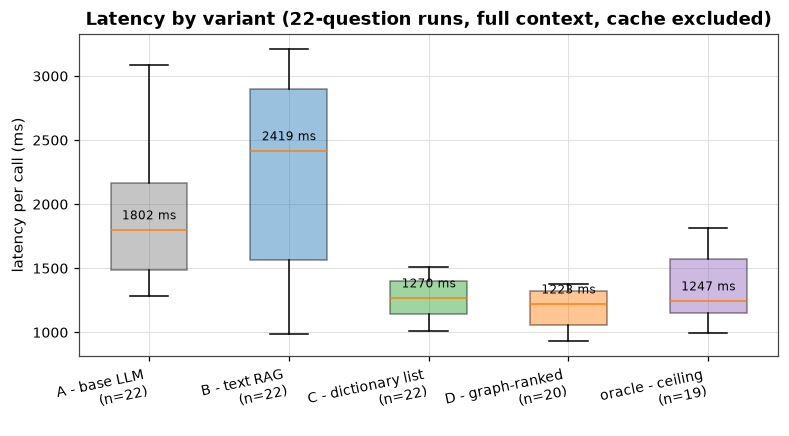

In [2]:
old_runs = al.find_runs()
old_runs = old_runs[(~old_runs["dry_run"]) & (old_runs["n_questions"] == 22)]
lat = pd.concat([al.load_answers(rid) for rid in old_runs["run_id"]], ignore_index=True)
lat = lat[(~lat["cache_hit"]) & lat["latency_ms"].notna()]
variants = ["A", "B", "C", "D", "oracle"]

fig, ax = plt.subplots(figsize=(8.2, 3.8))
data = [lat[lat["variant"] == v]["latency_ms"].to_numpy() for v in variants]
labels = [f"{al.VARIANT_LABELS[v]}\n(n={len(d)})" for v, d in zip(variants, data, strict=True)]
bp = ax.boxplot(data, tick_labels=labels, showfliers=False, patch_artist=True, widths=0.55)
for patch, v in zip(bp["boxes"], variants, strict=True):
    patch.set_facecolor(al.VARIANT_COLORS[v])
    patch.set_alpha(0.45)
for i in range(len(variants)):
    med = float(np.median(data[i]))
    ax.text(i + 1, med + 80, f"{med:.0f} ms", ha="center", fontsize=8)
ax.set_ylabel("latency per call (ms)")
ax.set_title("Latency by variant (22-question runs, full context, cache excluded)")
plt.xticks(rotation=12, ha="right")
al.save_figure(fig, "05_latency")
fig

> **Reading the chart.** All five variants on the same 22-question set with
> full context (D comes from a follow-up run with identical prompts; oracle
> has slightly fewer fresh calls - n is annotated). B is the slowest and
> widest: its prompt is a retrieval query plus three chunks, and provider
> variance dominates. A is slower than the structured variants despite having
> no context - its free-form answers are long (it describes a sense in prose),
> while C/D/oracle answer with an ID plus a short description. Treat these as
> operational signals, not a controlled benchmark.

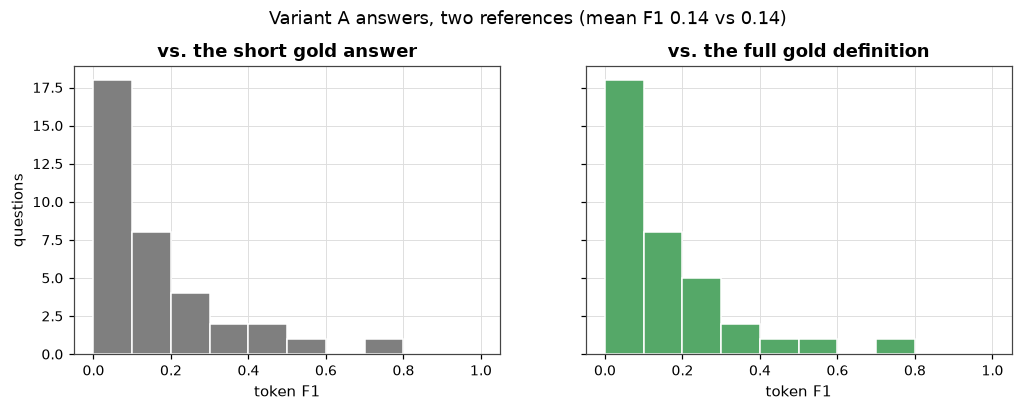

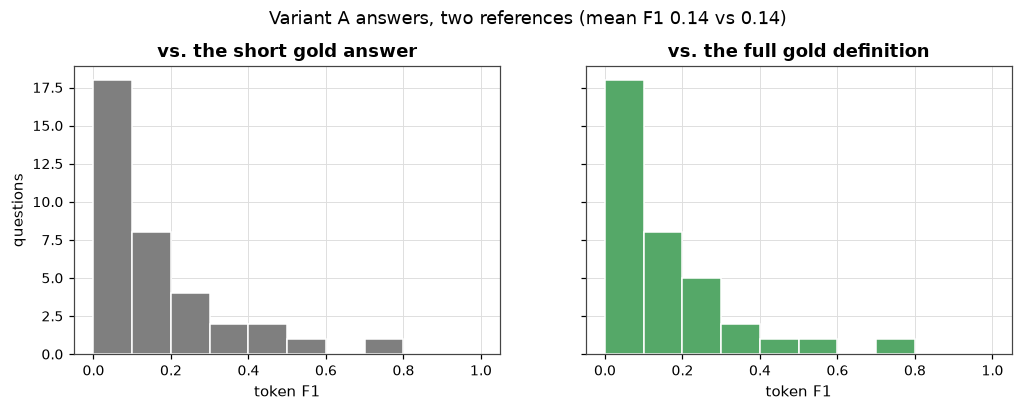

In [3]:
from elexai.eval.metrics import token_f1

a = full[full["variant"] == "A"].copy()
a["f1_short"] = [token_f1(x or "", g or "") for x, g in zip(a["answer"], a["gold_answer"], strict=True)]
a["f1_full"] = [
    token_f1(x or "", senses.loc[gid, "definition"] if gid in senses.index else "")
    for x, gid in zip(a["answer"], a["gold_sense_id"], strict=True)
]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
axes[0].hist(a["f1_short"], bins=np.linspace(0, 1, 11), color="#7f7f7f", edgecolor="white")
axes[0].set_title("vs. the short gold answer")
axes[0].set_xlabel("token F1")
axes[0].set_ylabel("questions")
axes[1].hist(a["f1_full"], bins=np.linspace(0, 1, 11), color="#55a868", edgecolor="white")
axes[1].set_title("vs. the full gold definition")
axes[1].set_xlabel("token F1")
fig.suptitle(f"Variant A answers, two references (mean F1 {a['f1_short'].mean():.2f} vs {a['f1_full'].mean():.2f})", y=1.03)
al.save_figure(fig, "05_a_metric")
fig

> **Reading the chart.** The two references give nearly identical scores
> (means 0.14 vs 0.14): the gold answers are mostly copies of the dictionary
> definitions, so "short vs full reference" is not the problem. The problem is
> that token-F1 is a **lexical** measure - A's paraphrase ("Rastlinski organ na
> brezi, ki je jeseni porumenel...") shares almost no tokens with "del
> rastline" even though it is a reasonable answer. Token-F1 is kept only as a
> rough sanity check for free-text answers; every headline comparison uses
> citation accuracy, which is exact.

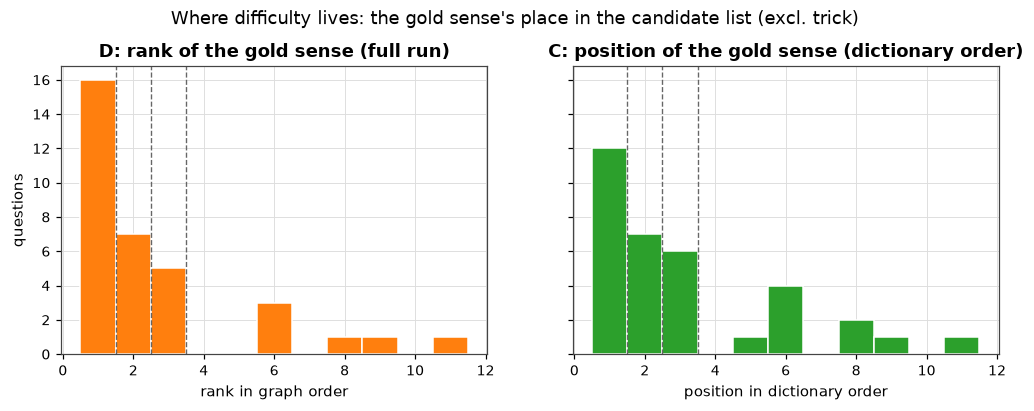

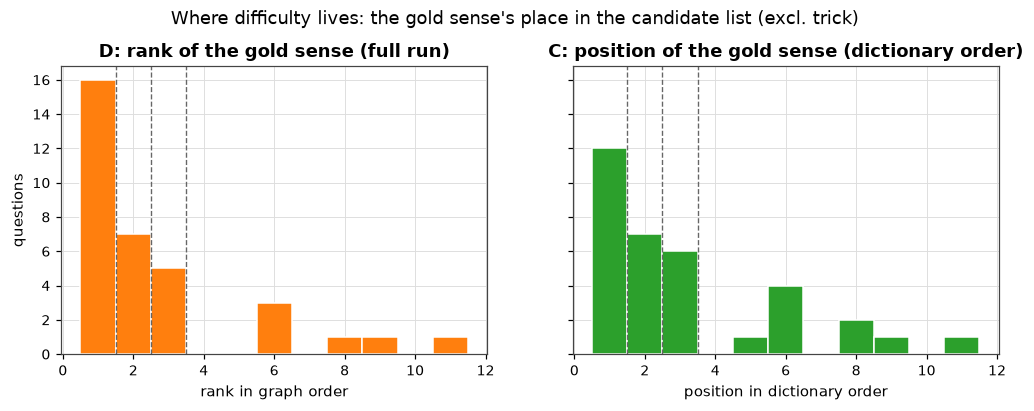

In [4]:
c_tab = full[full["variant"] == "C"].set_index("question_id")
d_tab = full[full["variant"] == "D"].set_index("question_id")
d_ranks = [int(d_tab.loc[q, "gold_rank"]) for q in d_tab.index if not d_tab.loc[q, "is_trick"] and pd.notna(d_tab.loc[q, "gold_rank"])]
c_pos = []
for q in c_tab.index:
    if c_tab.loc[q, "is_trick"]:
        continue
    gold = c_tab.loc[q, "gold_sense_id"]
    shown = list(c_tab.loc[q, "shown_ids"] or [])
    if gold in shown:
        c_pos.append(shown.index(gold) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
axes[0].hist(d_ranks, bins=np.arange(1, 13) - 0.5, color=al.VARIANT_COLORS["D"], edgecolor="white")
for cap in [1, 2, 3]:
    axes[0].axvline(cap + 0.5, ls="--", color="#666666", lw=0.9)
axes[0].set_title("D: rank of the gold sense (full run)")
axes[0].set_xlabel("rank in graph order")
axes[0].set_ylabel("questions")
axes[1].hist(c_pos, bins=np.arange(1, 13) - 0.5, color=al.VARIANT_COLORS["C"], edgecolor="white")
for cap in [1, 2, 3]:
    axes[1].axvline(cap + 0.5, ls="--", color="#666666", lw=0.9)
axes[1].set_title("C: position of the gold sense (dictionary order)")
axes[1].set_xlabel("position in dictionary order")
fig.suptitle("Where difficulty lives: the gold sense's place in the candidate list (excl. trick)", y=1.03)
al.save_figure(fig, "05_gold_rank_hist")
fig

> **Reading the chart.** Most gold senses are early under both orderings - but
> C's tail is much longer (positions up to 11), and the dashed lines show what
> each budget keeps: budget 1 keeps only the first slot, budget 3 the first
> three. The tails are exactly the questions where C and D diverge (notebook 3),
> and they are dominated by late, specific senses.

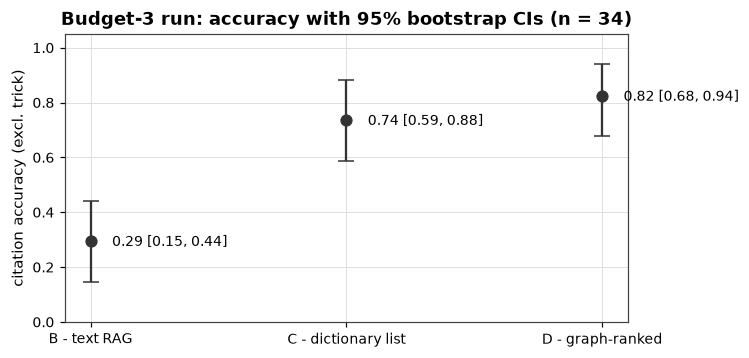

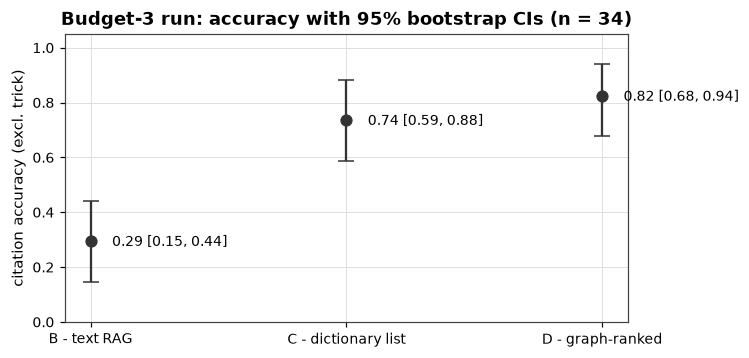

In [5]:
m = al.correctness_matrix(cap3, variants=("B", "C", "D"))
rows = []
for v in ["B", "C", "D"]:
    k = int(m[v].sum())
    n = len(m)
    lo, hi = al.bootstrap_ci(k, n)
    rows.append({"variant": v, "k": k, "n": n, "accuracy": k / n, "ci_low": lo, "ci_high": hi})
ci = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.6, 3.4))
x = np.arange(len(ci))
ax.errorbar(x, ci["accuracy"], yerr=[ci["accuracy"] - ci["ci_low"], ci["ci_high"] - ci["accuracy"]],
            fmt="o", ms=7, capsize=5, color="#333333")
for i, r in ci.iterrows():
    ax.annotate(f"{r['accuracy']:.2f} [{r['ci_low']:.2f}, {r['ci_high']:.2f}]", (i, r["accuracy"]),
                textcoords="offset points", xytext=(14, -3), fontsize=9)
ax.set_xticks(x, [al.VARIANT_LABELS[v] for v in ci["variant"]])
ax.set_ylim(0, 1.05)
ax.set_ylabel("citation accuracy (excl. trick)")
ax.set_title("Budget-3 run: accuracy with 95% bootstrap CIs (n = 34)")
al.save_figure(fig, "05_stats")
fig

In [6]:
rows = []
for cap in [1, 2, 3, 12]:
    mm = al.correctness_matrix(al.load_answers(run_of[cap]), variants=("C", "D"))
    b = int((mm["D"] & ~mm["C"]).sum())
    c = int((mm["C"] & ~mm["D"]).sum())
    rows.append({"comparison": f"D vs C, budget {cap}", "D wins": b, "C wins": c, "exact McNemar p": round(al.mcnemar_exact(b, c), 3)})
mm = al.correctness_matrix(cap3, variants=("B", "C"))
rows.append({"comparison": "C vs B, budget 3", "D wins": int((mm["C"] & ~mm["B"]).sum()), "C wins": int((mm["B"] & ~mm["C"]).sum()), "exact McNemar p": round(al.mcnemar_exact(int((mm["C"] & ~mm["B"]).sum()), int((mm["B"] & ~mm["C"]).sum())), 4)})
pd.DataFrame(rows)

,comparison,D wins,C wins,exact McNemar p
0,"D vs C, budget 1",7,1,0.0700
1,"D vs C, budget 2",4,0,0.1250
2,"D vs C, budget 3",3,0,0.2500
3,"D vs C, budget 12",0,0,1.0000
4,"C vs B, budget 3",19,4,0.0026


> **Reading the numbers.** The 95 % bootstrap CIs are wide (about ±0.15 with
> n = 34): any single pairwise comparison is underpowered. C vs D at budget 1
> reaches p ≈ 0.07; at budget 3 it is p ≈ 0.25. The *pattern* - D ahead at
> every budget, never behind - is the evidence; the individual p-values are
> not. C vs B, by contrast, is decisively separated (p < 0.001).

## What we learned (the transferable claims)

| # | Claim | Evidence from this pilot |
|---|---|---|
| 1 | **Saturation**: when the candidate set fits the context, sense selection is solved; residual error is inventory quality, not method. | Full run: C = D = oracle = 34/34 (excl. trick); the only errors are 2 flawed items. |
| 2 | **Budget crossover**: structured ordering pays off only when the budget is smaller than the candidate set, and the gain grows as the budget shrinks. | C vs D (excl. trick): +0.00 (all) -> +0.09 (3) -> +0.12 (2) -> +0.18 (1); D-only wins 0/3/4/7. |
| 3 | **Retrieval is the bottleneck for open semantic search** - at every budget. | B flat at ~29 %; recall@10 = 0.39; MRR 0.217; 78 % of top-1 retrievals from the wrong lemma. |
| 4 | **Definitional queries trap similarity search**: a query that quotes the source's definition retrieves the source, not the target. | Relations: B retrieved the source 6/6 and the gold in top-10 5/6, yet answered only 3/6 (50 %). |
| 5 | **The error decomposition moves with the budget**: full context -> composition/label noise; truncated -> coverage. | C: coverage errors 0 -> 9 -> 16 -> 24 as budget goes 12 -> 3 -> 2 -> 1; composition 0 throughout. |
| 6 | **Graph links buy coverage, not composition**: given the right candidate, the model's selection is identical with or without the graph. | D's gains over C are exactly the questions whose gold was outside C's first k; composition equal across C/D/oracle. |
| 7 | **Inventory granularity caps achievable accuracy**: benchmark construction matters as much as the model. | 2/36 items flawed by design (compound sense; near-duplicate senses) - all structured errors in the full regime. |

**What would change our mind / next steps**

- More questions: with 34 usable items, a +3-question difference is not
  significant; a harder pack (late senses, definition-disjoint relations) would
  both test the claims and give the statistics room.
- A semantic ranking feature (definition-vs-sentence meaning, not word overlap)
  to attack the remaining D misses.
- A lexicographer pass over the 36 drafts (and a decision on the two trick
  items: fix or keep as documented edge cases).
- Optional: a lemma-restricted variant of B ("B+") to separate candidate
  restriction from ranking inside the text-RAG paradigm.

## Reproducibility

Everything above is derived from committed configs and local runs:

```bash
uv run python -m elexai.runner configs/skeleton.yaml   # full context (budget 12)
uv run python -m elexai.runner configs/cap3.yaml       # budget 3
uv run python -m elexai.runner configs/cap2.yaml       # budget 2
uv run python -m elexai.runner configs/cap1.yaml       # budget 1
make eval RUN=<run_id>                                 # metrics + report.md
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/0*.ipynb
```

All numbers are pilot signals: questions are **drafts** until a lexicographer
verifies them; runs are single (temperature 0, one model); raw outputs are
cached and re-scorable offline. See `docs/DECISIONS.md` (D-018..D-024) for the
methodological details and known deviations.